<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Actividad_19_10_2026_Crescente_Mauricio_353564222.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Alumno Crescente Mauricio
#DNI: 35564222

# Actividad Práctica Completa: Procesamiento y Ciencia de Datos con Dataset Sintético

Esta guía práctica integrada reúne de manera exhaustiva todos los conceptos, metodologías y estándares de calidad de datos abordados a lo largo del programa de capacitación en Ciencia de Datos. Incluye la generación de un conjunto de datos sintético con errores reales inyectados intencionalmente y el desarrollo detallado paso a paso del pipeline de limpieza, análisis exploratorio, imputación de faltantes, tratamiento de outliers, transformación de variables y manejo de desbalanceo de clases con validación estricta para evitar la fuga de información (Data Leakage).


##1-Resumen Ejecutivo y Estructura del Pipeline

El objetivo central es transformar un dataset crudo de evaluación de riesgo crediticio, plagado de inconsistencias, tipos de datos incorrectos, valores atípicos y desbalanceo de clases, en un conjunto de características perfectamente limpio y preparado para modelos de Machine Learning.


### Estructura del Pipeline, Conceptos y Herramientas Clave

| # | Etapa del Pipeline | Conceptos Aplicados | Herramientas y Métodos clave |
| :--- | :--- | :--- | :--- |
| **1** | Diagnóstico y Auditoría | Dimensiones de calidad, Target Leakage, Unicidad | `.info()`, `.describe()`, `value_counts()` |
| **2** | Limpieza Operativa | Deduplicación, Casting de tipos, Sanitización de texto/moneda | `drop_duplicates()`, `pd.to_numeric()`, `np.where()` |
| **3** | Datos Faltantes | Mecanismos MCAR/MAR/MNAR, Imputación condicional | `dropna()`, `groupby().transform()`, `fillna()` |
| **4** | Tratamiento de Outliers | Detección univariante (IQR/Z-Score), Winsorización | `stats.zscore()`, `quantile()`, `np.clip()` |
| **5** | Partición Estratificada | Aislamiento estricto (Fit/Transform), Aislamiento de Test | `train_test_split(stratify=y)` |
| **6** | Transformación Avanzada | Escalado, Power Transforms, Codificación Nominal y Ordinal | `ColumnTransformer`, `PowerTransformer`, `OneHotEncoder` |
| **7** | Balanceo y Evaluación | Interpolación sintética SMOTE, Cost-Sensitive, Moving Threshold | `SMOTE`, `RandomForestClassifier`, `PR-AUC` |

##2-Generación del Dataset Sintético "Dirty Dataset"
El siguiente código genera el archivo sintético dataset_riesgo_crediticio_dirty.csv. El script inyecta intencionalmente duplicados exactos, fechas con formato heterogéneo, edades fuera de rango (-8, 150), ingresos expresados como texto formateado con símbolos monetarios y palabras sueltas ("Gratis"), una columna secundaria con más del 50% de faltantes, desbalanceo severo en la variable objetivo (94% / 6%) y una variable de fuga de información (Target Leakage) correspondiente a días de mora posteriores al crédito.


In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)
n_samples = 1000

# 1. Identificadores de clientes y duplicados
ids = np.random.randint(1000, 1500, size=n_samples)

# 2. Fechas con formatos heterogéneos e inconsistencias
fechas_base = ['2023-01-15', '15/02/2023', '2023.03.10', '10-Apr-2023', '1900-01-01', '2035-12-31', None]
fechas = np.random.choice(fechas_base, size=n_samples)

# 3. Edades con valores fuera de rango (-8, 150) y faltantes
edades = np.random.normal(loc=40, scale=12, size=n_samples)
edades[10:20] = -8
edades[21:30] = 150
edades[31:45] = np.nan

# 4. Ingreso Mensual guardado como texto con símbolos y errores
ingresos_num = np.random.exponential(scale=3000, size=n_samples) + 500
ingresos_str = [f"${x:,.2f}" for x in ingresos_num]
for i in range(50, 70):
    ingresos_str[i] = "Gratis"
for i in range(71, 90):
    ingresos_str[i] = np.nan

# 5. Monto del Crédito con asimetría positiva y outliers extremos
monto_credito = np.random.lognormal(mean=9, sigma=1.2, size=n_samples)
monto_credito[100:105] = 500000.0  # Outliers extremos

# 6. Estado Civil con inconsistencias de espacios y minúsculas/mayúsculas
estados = [' Soltero ', 'soltero', 'SOLTERO', 'Casado', 'CASADO', 'Divorciado ', 'Viudo']
estado_civil = np.random.choice(estados, size=n_samples)

# 7. Nivel Educativo (Variable Ordinal)
educacion = np.random.choice(['Primaria', 'Secundaria', 'Universitario', 'Postgrado'], size=n_samples)

# 8. Columna con >50% de valores faltantes
notas_auditoria = [np.nan] * n_samples
for i in range(0, 100):
    notas_auditoria[i] = "Revisión manual requerida"

# 9. Target Leakage (Variable futura que revela el target directamente)
target = np.random.choice([0, 1], size=n_samples, p=[0.94, 0.06])
dias_mora_posteriores = np.where(target == 1, np.random.randint(31, 180, size=n_samples), 0)

# Construcción del DataFrame original
df_sintetico = pd.DataFrame({
    'id_cliente': ids,
    'fecha_alta': fechas,
    'edad': edades,
    'ingreso_mensual_str': ingresos_str,
    'monto_credito': monto_credito,
    'estado_civil': estado_civil,
    'nivel_educativo': educacion,
    'notas_auditoria': notas_auditoria,
    'dias_mora_posteriores': dias_mora_posteriores, # Fuga de datos
    'incumplimiento': target
})

# Inyección deliberada de duplicados exactos
df_sintetico = pd.concat([df_sintetico, df_sintetico.iloc[0:20]], ignore_index=True)
df_sintetico.to_csv('dataset_riesgo_crediticio_dirty.csv', index=False)
print("Dataset sintético 'dataset_riesgo_crediticio_dirty.csv' generado exitosamente.")


Dataset sintético 'dataset_riesgo_crediticio_dirty.csv' generado exitosamente.


##3-Guía Paso a Paso de la Actividad Práctica

###Paso 1: Exploración Inicial, Diagnóstico de Calidad y Auditoría Previa
Objetivo: Inspeccionar la estructura tabular, diagnosticar las dimensiones de calidad (Completitud, Consistencia, Validez, Unicidad) y auditar posibles fuentes de Fuga de Datos (Target Leakage).
1. Cargar el conjunto de datos y obtener las métricas resumidas mediante .head(), .info() y .describe().
2. Analizar la proporción de clases de la variable objetivo incumplimiento con .value_counts(normalize=True).
3. Auditoría de Target Leakage: La variable dias_mora_posteriores contiene información registrada únicamente tras la ocurrencia del evento de incumplimiento. Su inclusión en la etapa de entrenamiento distorsionaría el modelo, por lo que debe ser eliminada del espacio de variables independientes.


In [ ]:
import pandas as pd
import numpy as np

# Carga e inspección básica
df_raw = pd.read_csv('dataset_riesgo_crediticio_dirty.csv')
print("--- Diagnóstico Estructural Inicial ---")
print(df_raw.info())
print("\n--- Distribución de la Variable Objetivo ---")
print(df_raw['incumplimiento'].value_counts(normalize=True))

# Eliminación preventiva de Target Leakage
df_clean = df_raw.drop(columns=['dias_mora_posteriores']).copy()


--- Diagnóstico Estructural Inicial ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_cliente             1020 non-null   int64  
 1   fecha_alta             868 non-null    object 
 2   edad                   1006 non-null   float64
 3   ingreso_mensual_str    1001 non-null   object 
 4   monto_credito          1020 non-null   float64
 5   estado_civil           1020 non-null   object 
 6   nivel_educativo        1020 non-null   object 
 7   notas_auditoria        120 non-null    object 
 8   dias_mora_posteriores  1020 non-null   int64  
 9   incumplimiento         1020 non-null   int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 79.8+ KB
None

--- Distribución de la Variable Objetivo ---
incumplimiento
0    0.941176
1    0.058824
Name: proportion, dtype: float64


###Paso 2: Limpieza Operativa, Deduplicación y Estandarización
Objetivo: Remover duplicados, corregir tipos de datos (Casting), estandarizar cadenas de texto y filtrar errores lógicos de negocio.
1. Deduplicación: Identificar y remover filas duplicadas con drop_duplicates(keep='first').
2. Normalización Categórica: Eliminar espacios sobrantes y corregir diferencias de mayúsculas/minúsculas en estado_civil usando .str.strip().str.title().
3. Casting y Sanitización Monetaria: Transformar la columna de ingresos sustituyendo el símbolo $, comas y convirtiendo "Gratis" a valor cero antes del parseo a flotante.
4. Formatos Temporales: Homogeneizar las fechas heterogéneas con pd.to_datetime(..., format='mixed', errors='coerce').
5. Reglas de Validez de Rangos: Filtrar edades fuera del rango biológicamente válido [18, 100] asignándoles np.nan mediante np.where().


In [ ]:
# 1. Deduplicación
df_clean = df_clean.drop_duplicates(keep='first').reset_index(drop=True)

# 2. Normalización de texto
df_clean['estado_civil'] = df_clean['estado_civil'].astype(str).str.strip().str.title()

# 3. Limpieza y casting de valores monetarios
df_clean['ingreso_mensual'] = (
    df_clean['ingreso_mensual_str']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.replace('Gratis', '0', regex=False)
)
df_clean['ingreso_mensual'] = pd.to_numeric(df_clean['ingreso_mensual'], errors='coerce')
df_clean = df_clean.drop(columns=['ingreso_mensual_str'])

# 4. Homogeneización de fechas
df_clean['fecha_alta'] = pd.to_datetime(df_clean['fecha_alta'], format='mixed', errors='coerce')

# 5. Corrección de rango de edad
df_clean['edad'] = np.where(
    (df_clean['edad'] < 18) | (df_clean['edad'] > 100),
    np.nan,
    df_clean['edad']
)


###Paso 3: Visualización y Tratamiento de Datos Faltantes
**Objetivo:** Evaluar los patrones de faltantes (MCAR, MAR, MNAR) y aplicar eliminación por umbral e imputación condicional/estadística.
1. **Eliminación por Umbral:** La columna notas_auditoria supera el 50% de registros nulos y carece de poder predictivo, por lo que se descarta con dropna(axis=1, thresh=umbral).
2. **Imputación Condicional por Grupo:** Para preservar la distribución original, los valores faltantes en edad se imputan con la mediana calculada dentro de cada nivel de nivel_educativo mediante groupby().transform().
3. **Imputación Numérica y Categórica General:** Rellenar ingreso_mensual con la mediana y estado_civil con la moda (valor más frecuente).


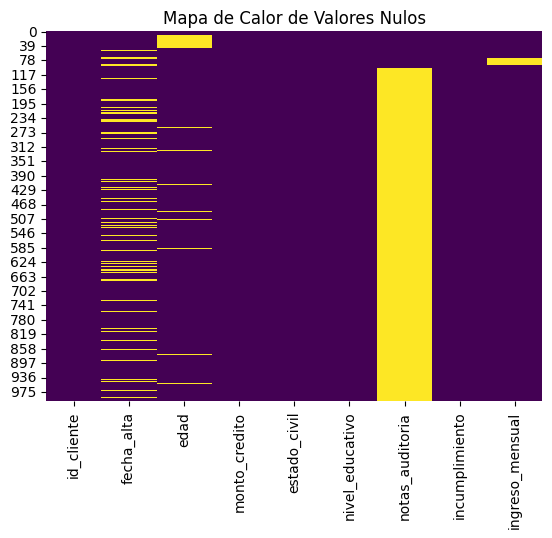

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualización de matriz de nulos
sns.heatmap(df_clean.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de Calor de Valores Nulos')
plt.show()

# 1. Eliminación por umbral (columnas con >50% de nulos)
umbral_50 = len(df_clean) * 0.5
df_clean = df_clean.dropna(axis=1, thresh=umbral_50)

# 2. Imputación condicional de edad por grupo educativo
df_clean['edad'] = df_clean.groupby('nivel_educativo')['edad'].transform(lambda x: x.fillna(x.median()))

# 3. Imputaciones simples
df_clean['ingreso_mensual'] = df_clean['ingreso_mensual'].fillna(df_clean['ingreso_mensual'].median())
df_clean['estado_civil'] = df_clean['estado_civil'].fillna(df_clean['estado_civil'].mode()[0])


###Paso 4: Detección y Tratamiento de Outliers
Objetivo: Cuantificar y mitigar la presencia de valores atípicos extremados sin eliminar información útil.


####**Comparativa de métodos**
| Método | Fórmula / Criterio | Aplicación |
| :--- | :--- | :--- |
| **1. Rango Intercuartílico (IQR)** | Límite = $Q3 + 1.5 \times (Q3 - Q1)$ | Detección en distribuciones asimétricas (Monto Crédito) |
| **2. Z-Score** | $Z = (x - \mu) / \sigma$, $|Z| > 3$ | Detección en distribuciones con tendencia gaussiana |
| **3. Winsorización** | `np.clip(x, p1, p99)` | Sustitución de extremos por percentiles 1 y 99 |

In [ ]:
from scipy import stats

# Identificación por Z-Score en ingreso_mensual
z_scores = np.abs(stats.zscore(df_clean['ingreso_mensual']))
print(f"Outliers detectados por Z-Score (>3): {len(df_clean[z_scores > 3])}")

# Tratamiento por Winsorización en monto_credito (Percentiles 1% y 99%)
p1 = df_clean['monto_credito'].quantile(0.01)
p99 = df_clean['monto_credito'].quantile(0.99)
df_clean['monto_credito_winsorized'] = np.clip(df_clean['monto_credito'], p1, p99)


Outliers detectados por Z-Score (>3): 18


###Paso 5: Partición Estratificada y Aisle de Datos (Train-Test Split)
Regla de Oro: La división del dataset debe realizarse antes de cualquier operación de escalado, imputación global o codificación.
1. Utilizar train_test_split con test_size=0.20 y fijar la semilla aleatoria.
2. Aplicar stratify=y para garantizar que la proporción del target desbalanceado (6% positivos) sea idéntica tanto en el set de entrenamiento como en el de testeo.


In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean[['edad', 'ingreso_mensual', 'monto_credito_winsorized', 'estado_civil', 'nivel_educativo']]
y = df_clean['incumplimiento']

# Partición estratificada obligatoria
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tamaño Train: {X_train.shape}, Tamaño Test: {X_test.shape}")


Tamaño Train: (800, 5), Tamaño Test: (200, 5)


###Paso 6: Transformación de Variables e Integración en Pipeline
Objetivo: Diseñar una arquitectura de preprocesamiento robusta mediante ColumnTransformer aplicando .fit() exclusivamente en el conjunto de entrenamiento.
1. Power Transform (Yeo-Johnson): Estabilizar la varianza y normalizar la distribución asimétrica del monto del crédito.
2. StandardScaler: Estandarizar variables numéricas continuas (=0,=1).
3. OneHotEncoder: Codificar variables nominales con drop='first' para evitar colinealidad y handle_unknown='ignore'.
4. OrdinalEncoder: Mapear categorías ordenadas de educación ('Primaria' < 'Secundaria' < 'Universitario' < 'Postgrado').


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer

# Definición de columnas
num_cols = ['edad', 'ingreso_mensual']
cat_nominal = ['estado_civil']
cat_ordinal = ['nivel_educativo']

orden_educacion = [['Primaria', 'Secundaria', 'Universitario', 'Postgrado']]

# Ensamblado del preprocesador
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('pow', PowerTransformer(method='yeo-johnson'), ['monto_credito_winsorized']),
        ('cat_nom', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_nominal),
        ('cat_ord', OrdinalEncoder(categories=orden_educacion), cat_ordinal)
    ]
)

# Ajuste EXCLUSIVO sobre Train y transformación de ambos sets
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)


###Paso 7: Tratamiento de Desbalanceo con SMOTE, Entrenador y Evaluación
**Objetivo:** Balancear la distribución de la clase minoritaria mediante generación sintética vectorial y optimizar el rendimiento predictivo.

**Ecuación de Interpolación de SMOTE:**
x_sintético = x_i + λ * (x_vecino - x_i) donde λ ~ U(0, 1)
1. CRÍTICO: Aplicar SMOTE únicamente sobre el set de entrenamiento transformado (X_train_trans). Jamás debe tocarse el set de evaluación de prueba.
2. Ajuste de Umbral (Moving Threshold): En lugar de usar la regla por defecto (p0.50), reducir el umbral de decisión a p0.25 para maximizar la sensibilidad (Recall) en la detección de posibles morosos.


In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc

# 1. SMOTE exclusivo en Train
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_trans, y_train)

# 2. Entrenamiento de Modelo Cost-Sensitive
clf = RandomForestClassifier(random_state=42, class_weight='balanced')
clf.fit(X_train_res, y_train_res)

# 3. Predicción de probabilidades en Test
y_probs = clf.predict_proba(X_test_trans)[:, 1]

# 4. Ajuste de Umbral de Decisión (Moving Threshold a 0.25)
y_pred_custom = (y_probs >= 0.25).astype(int)

# Evaluación de resultados
print("--- Matriz de Confusión (Umbral 0.25) ---")
print(confusion_matrix(y_test, y_pred_custom))

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred_custom))

precision, recall, _ = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recall, precision)
print(f"Área Bajo la Curva Precision-Recall (PR-AUC): {pr_auc:.4f}")


--- Matriz de Confusión (Umbral 0.25) ---
[[147  41]
 [ 12   0]]

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.92      0.78      0.85       188
           1       0.00      0.00      0.00        12

    accuracy                           0.73       200
   macro avg       0.46      0.39      0.42       200
weighted avg       0.87      0.73      0.80       200

Área Bajo la Curva Precision-Recall (PR-AUC): 0.0394


##4-Lista de Comprobación Final (Checklist Pre-Entrenamiento)


### Checklist de Validación de Modelado

| # | Requisito Técnico | Riesgo si no se cumple | Verificación |
| :---: | :--- | :--- | :---: |
| **1** | Partición Train/Test realizada previa a transformaciones | Fuga de Información (Data Leakage) | ✓ |
| **2** | Muestreo estratificado en la división del target | Distorsión en la distribución de la variable objetivo | ✓ |
| **3** | Auditoría e implementación de `fit()` solo en Train | Contaminación estadística de parámetros de evaluación | ✓ |
| **4** | Manejo explícito de categorías desconocidas en Test | Excepciones de código en tiempo de ejecución | ✓ |
| **5** | SMOTE ejecutado exclusivamente sobre el conjunto Train | Métricas de validación falsas e irreales | ✓ |
| **6** | Evaluación mediante PR-AUC y F1-Score en lugar de Accuracy | **Paradoja** de la Exactitud en datos desbalanceados | ✓ |